[*********************100%***********************]  3 of 3 completed
[*********************100%***********************]  1 of 1 completed


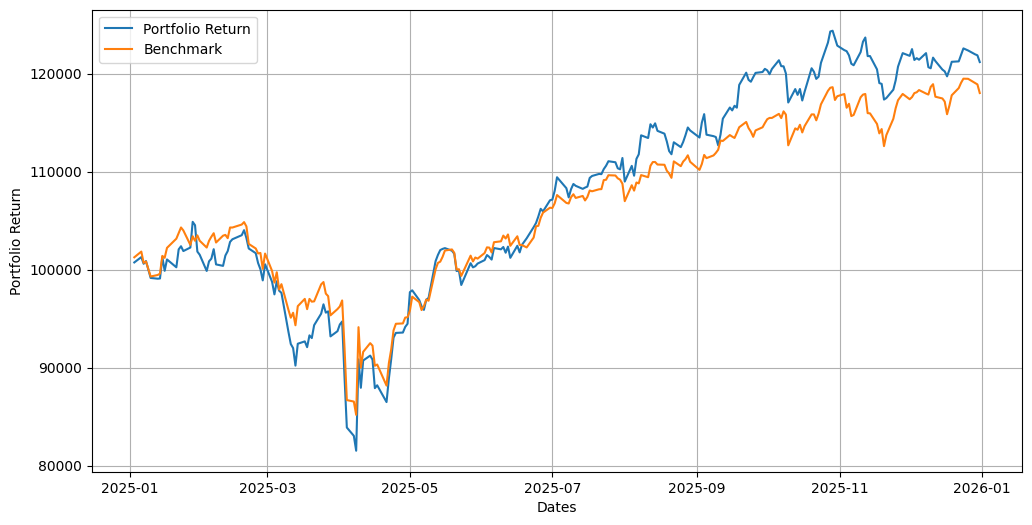

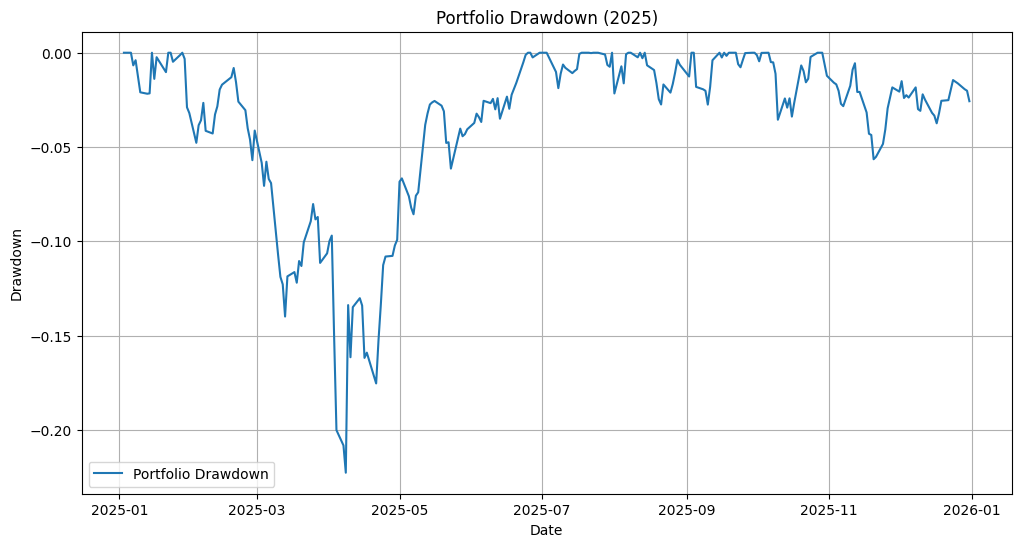

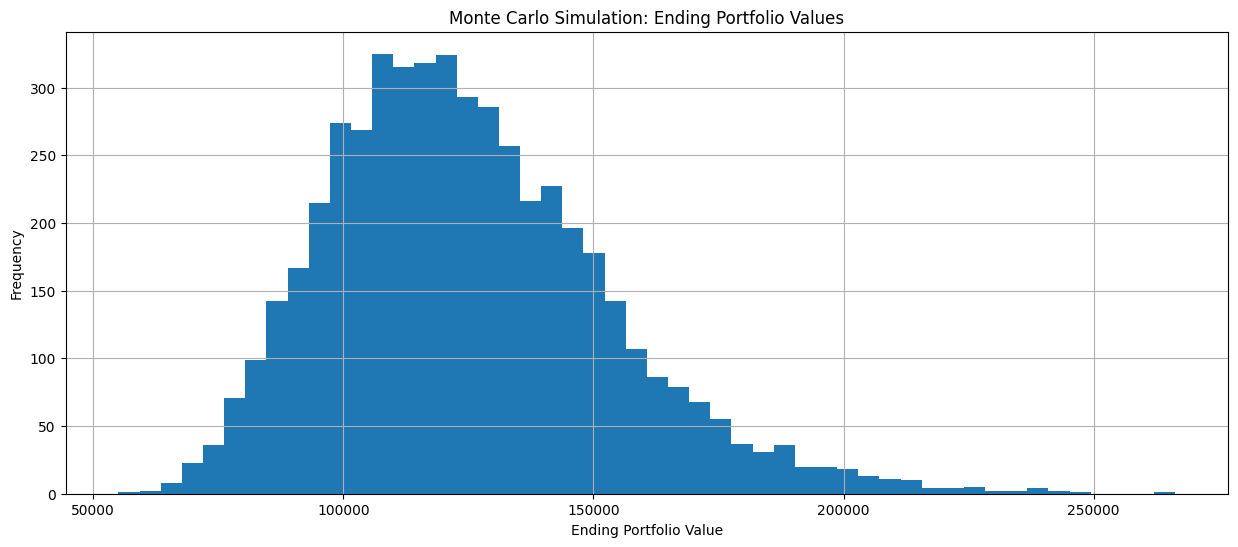

                         Metric    Value
0        Portfolio Total Return   21.17%
1        Benchmark Total Return   18.01%
2   Annualized Portfolio Return   21.90%
3   Annualized Benchmark Return   18.64%
4      Annualized Active Return    3.26%
5          Portfolio Volatility   22.36%
6                  Sharpe Ratio     0.80
7             Information Ratio     0.33
8                Portfolio Beta     1.03
9                  Jensen Alpha    2.88%
10             Maximum Drawdown  -22.27%
             Risk Metric       Value
0          95% Daily VaR       1.80%
1      95% Daily VaR ($)   $1,802.15
2          99% Daily VaR       3.66%
3      99% Daily VaR ($)   $3,655.65
4         95% Daily CVaR       3.05%
5     95% Daily CVaR ($)   $3,048.34
6         99% Daily CVaR       5.28%
7     99% Daily CVaR ($)   $5,280.05
8  Maximum Drawdown Date  2025-04-08
             Monte Carlo Metric        Value
0             Mean Ending Value  $124,749.60
1           Median Ending Value  $121,421.12
2  

In [67]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
#portflio- Microsoft, Apple and JPMorgan Chase
#Data Collection
Investment = 100000
weights = np.array([0.40,0.35,0.25])
stocks = yf.download(["MSFT","AAPL", "JPM"], start = "2025-01-01",
                     end= "2026-01-01", auto_adjust = True)
#Data Cleaning
#print(weights.sum())
close_prices = stocks["Close"][["MSFT","AAPL","JPM"]]
#print(close_prices.head(5))
missing_values = close_prices.isnull().sum()
#print(missing_values)
#print(close_prices.shape)
daily_returns = close_prices.pct_change().dropna()

#Portfolio Construction
weighted_portfolio_returns = daily_returns.dot(weights)
#print(daily_returns.head())
#print(weighted_portfolio_returns.head())
cumulative_returns = (1+weighted_portfolio_returns).cumprod()-1
daily_portfolio_value = Investment*(1+cumulative_returns)
ending_value = daily_portfolio_value.iloc[-1]
total_profit_loss = ending_value -  Investment

#Benchmark Comparison
Benchmark = yf.download("SPY", start = "2025-01-01", end="2026-01-01",
                        auto_adjust = True)

B_close_prices = Benchmark["Close"].squeeze()
Benchmark_daily_return = B_close_prices.pct_change().dropna()
Benchmark_cum_return = (1+Benchmark_daily_return).cumprod()-1
#print(Benchmark_cum_return.iloc[-1])

comparison = pd.concat([weighted_portfolio_returns, Benchmark_daily_return],
                       axis = 1)

comparison.columns = ["Portfolio", "Benchmark"]
comparison = comparison.dropna()
#print(comparison.shape)
#print(comparison.head(5))
comparison["Active Return"] = comparison["Portfolio"] - comparison["Benchmark"]

#Performance Metrics
annualised_active_return = comparison["Active Return"].mean()*252
tracking_error = comparison["Active Return"].std() * np.sqrt(252)
information_ratio = annualised_active_return/tracking_error

#Risk-Ajusted Metrics
cov_portfolio_benchmark = comparison["Portfolio"].cov(comparison["Benchmark"])
benchmark_var = comparison["Benchmark"].var()
portfolio_beta = cov_portfolio_benchmark/benchmark_var
risk_free_rate = 0.04
annualized_portfolio_return = comparison["Portfolio"].mean()*252
annualized_benchmark_return = comparison["Benchmark"].mean()*252
jensen_alpha = annualized_portfolio_return - (risk_free_rate +
               portfolio_beta*(annualized_benchmark_return- risk_free_rate))
annual_vol = comparison["Portfolio"].std() * np.sqrt(252)
sharpe_ratio = (annualized_portfolio_return - risk_free_rate) / annual_vol

#Downside Risk
portfolio_growth = Investment * (1 + comparison["Portfolio"]).cumprod()
peak = peak = portfolio_growth.cummax().clip(lower=Investment)
drawdown =(portfolio_growth - peak) / peak
max_drawdown = drawdown.min()
max_drawdown_date = drawdown.idxmin()

Var_95 = -np.percentile(comparison["Portfolio"],5)
Var_95_dollar = Investment* Var_95
Var_99 = -np.percentile(comparison["Portfolio"], 1)
Var_99_dollar = Investment * Var_99
CVar_95 = -comparison["Portfolio"][comparison["Portfolio"]<= -Var_95].mean()
CVar_95_dollar = Investment * CVar_95
CVar_99 = -comparison["Portfolio"][comparison["Portfolio"]<= -Var_99].mean()
CVar_99_dollar = Investment * CVar_99

#Monte Carlo Simulation
daily_mean = comparison["Portfolio"].mean()
daily_vol = comparison["Portfolio"].std()
simulation_day = 252
num_simulation = 5000
ending_values = []
rng = np.random.default_rng(42)
for i in range(num_simulation):
  simulated_returns = rng.normal(loc= daily_mean, scale=daily_vol,
                                      size = simulation_day )
  simulated_portfolio_values = Investment * ((1+simulated_returns).cumprod())
  ending_values.append(simulated_portfolio_values[-1])
simulated_mean = np.mean(ending_values)
ending_values = np.array(ending_values )
median_ending_values = np.percentile(ending_values, 50)
ending_values_95 = np.percentile(ending_values, 95)
ending_values_5 = np.percentile(ending_values,5)
profit_prob = len(ending_values[ending_values> Investment])/ num_simulation
loss_prob = len(ending_values[ending_values<Investment])/num_simulation

#Visualizations
portfolio_growth = Investment * (1 + comparison["Portfolio"]).cumprod()
benchmark_growth = Investment * (1 + comparison["Benchmark"]).cumprod()
plt.figure(figsize=[12,6])
plt.plot(portfolio_growth.index, portfolio_growth,
         label= "Portfolio Return")
plt.plot(benchmark_growth.index, benchmark_growth,
         label="Benchmark" )
plt.xlabel("Dates")
plt.ylabel("Portfolio Return")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 6))

plt.plot(drawdown.index, drawdown,
         label="Portfolio Drawdown")

plt.title("Portfolio Drawdown (2025)")
plt.xlabel("Date")
plt.ylabel("Drawdown")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize= [15,6])
plt.hist(ending_values,bins= 50)
plt.title("Monte Carlo Simulation: Ending Portfolio Values")
plt.ylabel("Frequency")
plt.xlabel("Ending Portfolio Value")
plt.grid(True)
plt.show()

#Results Summary
performance_summary = {
    "Portfolio Total Return": f"{(portfolio_growth.iloc[-1] / Investment-1):.2%}" ,
    "Benchmark Total Return": f"{(benchmark_growth.iloc[-1] / Investment-1):.2%}",
    "Annualized Portfolio Return": f"{annualized_portfolio_return:.2%}",
    "Annualized Benchmark Return": f"{annualized_benchmark_return:.2%}",
    "Annualized Active Return": f"{annualised_active_return:.2%}",
    "Portfolio Volatility": f"{annual_vol:.2%}",
    "Sharpe Ratio": f"{sharpe_ratio:.2f}",
    "Information Ratio": f"{information_ratio:.2f}",
    "Portfolio Beta": f"{portfolio_beta:.2f}",
    "Jensen Alpha": f"{jensen_alpha:.2%}",
    "Maximum Drawdown": f"{max_drawdown:.2%}"
}
performance_summary_df = pd.DataFrame(performance_summary.items(),
                                     columns = ["Metric", "Value"])
print(performance_summary_df)

risk_summary = {
    "95% Daily VaR": f"{Var_95:.2%}",
    "95% Daily VaR ($)": f"${Var_95_dollar:,.2f}",
    "99% Daily VaR": f"{Var_99:.2%}",
    "99% Daily VaR ($)": f"${Var_99_dollar:,.2f}",
    "95% Daily CVaR": f"{CVar_95:.2%}",
    "95% Daily CVaR ($)": f"${CVar_95_dollar:,.2f}",
    "99% Daily CVaR": f"{CVar_99:.2%}",
    "99% Daily CVaR ($)": f"${CVar_99_dollar:,.2f}",
    "Maximum Drawdown Date": str(max_drawdown_date.date())}
risk_summary_df = pd.DataFrame(
    risk_summary.items(),
    columns=["Risk Metric", "Value"])
print(risk_summary_df)

monte_carlo_summary = {
    "Mean Ending Value": f"${simulated_mean:,.2f}",
    "Median Ending Value": f"${median_ending_values:,.2f}",
    "5th Percentile Ending Value": f"${ending_values_5:,.2f}",
    "95th Percentile Ending Value": f"${ending_values_95:,.2f}",
    "Probability of Profit": f"{profit_prob:.2%}",
    "Probability of Loss": f"{loss_prob:.2%}"}

monte_carlo_summary_df = pd.DataFrame(
    monte_carlo_summary.items(),
    columns=["Monte Carlo Metric", "Value"])

print(monte_carlo_summary_df)